# 04 传播动力学：SIS / SIR / 任意仓室模型

`honet.contagion` 把传播过程抽象成**规格驱动**的形式：一个模型 = 一组仓室
+ 两条转移规则（感染、恢复）。内置 SIS/SIR/SIRS/SIER/SEIR/SI，也可以自己注册。

| 主题 | API |
| --- | --- |
| 模型注册表 | `available_models` / `get_model` / `register_model` / `CompartmentModel` |
| 感染率表 | `generate_tau` |
| **逐时间点序列** | `random_discrete_sis` / `random_gillespie_sir` |
| 统一入口 | `simulate`（返回**事件流**，见下方警告） |
| 相图 | `sis_phase` / `classify_point` |
| 控制 | `discrete_sis_control` / `discrete_sir_control` |

> ## ⚠️ 先分清两种返回格式
>
> | 入口 | 返回 | 适合 |
> | --- | --- | --- |
> | `random_discrete_sis(...)` | `(t, S, I)`，**逐时间点**的计数列表 | 画传播曲线、算峰值 |
> | `simulate(...)` | 元组，但每个元素是**事件序列**（状态变化点） | 事件级分析 |
>
> 想做时间序列分析就用 `random_discrete_sis`。用 `simulate` 画曲线会得到
> 只有几个点的"曲线"——那不是 bug，是事件驱动的本质。
>
> 另外 `honet.contagion` 全部接收 **hypernetx 超图**。

In [1]:
import hypernetx as hnx
import matplotlib.pyplot as plt

import honet

# 图表含中文，需显式指定支持中文的字体，否则标题会显示成方框
# （并刷出一大堆 "Glyph missing from font" 警告）。
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False  # 负号正常显示

# 一张有明确结构的小超图：两个 3 人小组 + 一条桥接边
H = hnx.Hypergraph(
    {
        "g1": ["a", "b", "c"],
        "g2": ["d", "e", "f"],
        "bridge": ["c", "d"],
    }
)
print("规模:", H.shape)
print("超边:", list(H.edges))

规模: (6, 3)
超边: ['g1', 'g2', 'bridge']


## 1. 模型注册表

`get_model` 返回 `CompartmentModel` 规格对象，包含仓室名、感染/恢复规则等。

In [2]:
print("可用模型:", honet.contagion.available_models())

sis = honet.contagion.get_model("SIS")
print("\nSIS 规格:")
print("  仓室:", sis.states)
print("  易感仓室:", sis.susceptible)
print("  感染仓室:", sis.infected)
print("  说明:", sis.description)

可用模型: ('SEIR', 'SI', 'SIER', 'SIR', 'SIRS', 'SIS')

SIS 规格:
  仓室: ('S', 'I')
  易感仓室: S
  感染仓室: ('I',)
  说明: 易感—感染—易感：康复后不产生免疫，可反复感染。


## 2. 感染率表：为什么是字典而不是一个数

**高阶交互的传染强度依赖于参与人数**。三人同处一室的风险不等于两次两人
接触之和。所以 `tau` 是 `{超边大小: 感染率}` 的字典。

In [3]:
tau = {2: 0.2, 3: 0.5}
print("手写感染率表:", tau)
print("含义: 2 人接触 -> 0.2, 3 人接触 -> 0.5（后者更高，体现高阶传染的超线性）")

# `generate_tau` 按规则批量生成。注意 `type="fixed"` 是**所有边大小取同一个值**，
# 只用到 beta[0]——它不是"按大小递增"。想要随大小变化要用 size_based。
fixed = honet.contagion.generate_tau(H, beta=[0.1, 0.3], type="fixed")
print("\ntype='fixed'（全部统一为 beta[0]）:", fixed)

size_based = honet.contagion.generate_tau(H, beta=[0.1, 0.3], type="size_based")
print("type='size_based'（beta[0] × 边大小）:", size_based)

sum_based = honet.contagion.generate_tau(H, beta=[0.1, 0.3], type="sum_based")
print("type='sum_based'（按大小占比分配）:", {k: round(v, 4) for k, v in sum_based.items()})

手写感染率表: {2: 0.2, 3: 0.5}
含义: 2 人接触 -> 0.2, 3 人接触 -> 0.5（后者更高，体现高阶传染的超线性）

type='fixed'（全部统一为 beta[0]）: {2: 0.1, 3: 0.1}
type='size_based'（beta[0] × 边大小）: {2: 0.2, 3: 0.30000000000000004}
type='sum_based'（按大小占比分配）: {2: 0.04, 3: 0.06}


## 3. 跑一次 SIS 模拟（逐时间点）

`random_discrete_sis` 返回 `(t, S, I)` 三个等长列表。

In [4]:
GAMMA = 0.3
TAU = {2: 0.2, 3: 0.5}

t, n_sus, n_inf = honet.contagion.random_discrete_sis(
    H,
    tau=TAU,
    gamma=GAMMA,
    rho=0.2,  # 初始感染比例（与 initial_infecteds 互斥）
    tmax=60,
    dt=1.0,
    seed=1,
)

print("返回三个列表，长度:", len(t), len(n_sus), len(n_inf))
print("t 前 6:", t[:6])
print("n_sus 前 6:", n_sus[:6])
print("n_inf 前 6:", n_inf[:6])

返回三个列表，长度: 61 61 61
t 前 6: [0, 1.0, 2.0, 3.0, 4.0, 5.0]
n_sus 前 6: [5, 4, 5, 4, 5, 4]
n_inf 前 6: [1, 2, 1, 2, 1, 2]


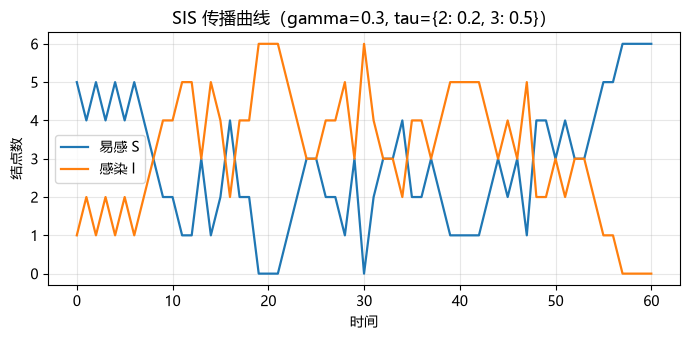

峰值感染数: 6
末态感染数: 0


In [5]:
plt.figure(figsize=(7, 3.5))
plt.plot(t, n_sus, label="易感 S", linewidth=1.6)
plt.plot(t, n_inf, label="感染 I", linewidth=1.6)
plt.xlabel("时间")
plt.ylabel("结点数")
plt.title(f"SIS 传播曲线（gamma={GAMMA}, tau={TAU}）")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"峰值感染数: {max(n_inf)}")
print(f"末态感染数: {n_inf[-1]}")

## 4. 对比 SIS 与 SIR：恢复后是否重新易感

这是两个模型唯一的本质区别：

- **SIS**：康复后回到易感态，可反复感染 → 可能形成**地方性流行**
- **SIR**：康复后获得免疫 → 疫情最终**熄灭**（`I` 归零）

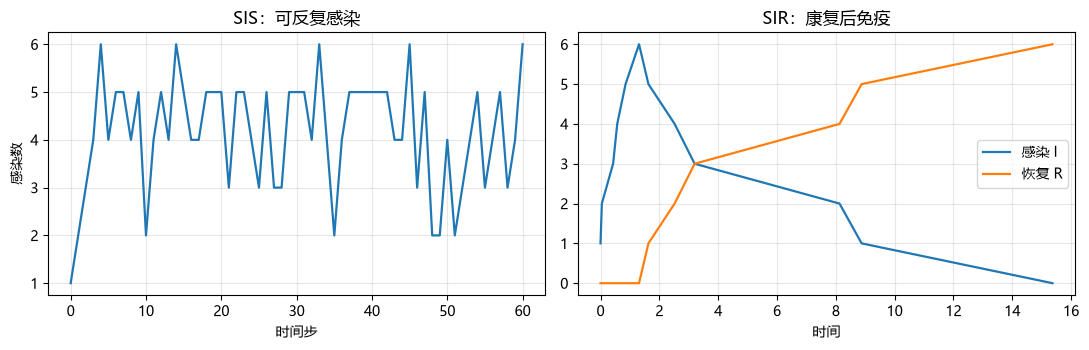

SIS 末态感染数: 6
SIR 末态感染数: 0（应为 0）


In [6]:
# 用这组参数让 SIS 保持流行（末态 6）、SIR 熄灭（末态 0），对比才鲜明
TAU_HIGH = {2: 0.3, 3: 0.7}
GAMMA_SIS = 0.3

_, S_sis, I_sis = honet.contagion.random_discrete_sis(
    H,
    tau=TAU_HIGH,
    gamma=GAMMA_SIS,
    rho=0.2,
    tmax=60,
    dt=1.0,
    seed=3,
)

t_sir, S_sir, I_sir, R_sir = honet.contagion.random_gillespie_sir(
    H,
    tau=TAU_HIGH,
    gamma=GAMMA_SIS,
    rho=0.2,
    tmax=60,
    seed=3,
)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))

axes[0].plot(range(len(I_sis)), I_sis, linewidth=1.6)
axes[0].set_title("SIS：可反复感染")
axes[0].set_xlabel("时间步")
axes[0].set_ylabel("感染数")
axes[0].grid(alpha=0.3)

axes[1].plot(t_sir, I_sir, label="感染 I", linewidth=1.6)
axes[1].plot(t_sir, R_sir, label="恢复 R", linewidth=1.6)
axes[1].set_title("SIR：康复后免疫")
axes[1].set_xlabel("时间")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(f"SIS 末态感染数: {I_sis[-1]}")
print(f"SIR 末态感染数: {I_sir[-1]}（应为 0）")

## 5. 全部内置模型一览

六个模型的仓室结构各不相同，`get_model` 可以逐个查出来。

In [7]:
print("全部内置模型:")
for name in honet.contagion.available_models():
    spec = honet.contagion.get_model(name)
    print(f"  {name:6s} 仓室={spec.states}  说明={spec.description}")

全部内置模型:
  SEIR   仓室=('S', 'E', 'I', 'R')  说明=易感—暴露—感染—恢复：与 SIER 同构，暴露期先于感染期。
  SI     仓室=('S', 'I')  说明=易感—感染：感染后不恢复，用于研究纯扩散过程。
  SIER   仓室=('S', 'E', 'I', 'R')  说明=易感—暴露—感染—恢复：感染后先经历无传染性的潜伏期，再转为有传染性。
  SIR    仓室=('S', 'I', 'R')  说明=易感—感染—恢复：康复后获得永久免疫，不再被感染。
  SIRS   仓室=('S', 'I', 'R')  说明=易感—感染—恢复—易感：免疫有时效，康复者会重新变为易感。
  SIS    仓室=('S', 'I')  说明=易感—感染—易感：康复后不产生免疫，可反复感染。


## 6. 传播的随机性

同样的参数、不同的 `seed`，曲线会不同——这是随机过程的本质。
做结论时必须跑多次取平均，不能只看一条曲线。

注意：下面 10 次用的是**同一组参数**，波动来自随机性本身。

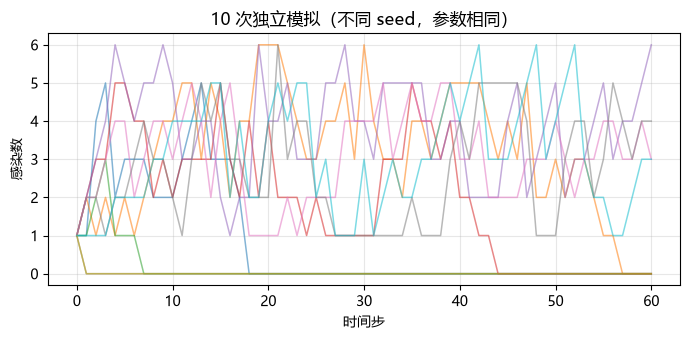

末态感染数: 最小=0, 最大=6, 均值=1.60


In [8]:
plt.figure(figsize=(7, 3.5))
final_counts = []
for seed in range(10):
    _, _, infected = honet.contagion.random_discrete_sis(
        H,
        tau=TAU,
        gamma=GAMMA,
        rho=0.2,
        tmax=60,
        dt=1.0,
        seed=seed,
    )
    plt.plot(range(len(infected)), infected, alpha=0.55, linewidth=1.1)
    final_counts.append(infected[-1])

plt.xlabel("时间步")
plt.ylabel("感染数")
plt.title("10 次独立模拟（不同 seed，参数相同）")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

mean_final = sum(final_counts) / len(final_counts)
print(f"末态感染数: 最小={min(final_counts)}, 最大={max(final_counts)}, 均值={mean_final:.2f}")

## 7. 阈值行为：调低感染率让疫情熄灭

上组参数（`tau=(0.2, 0.5)`、`gamma=0.3`）会持续流行。把感染率调低一个
数量级，同样的网络就会熄灭——这就是**传播阈值**。

In [9]:
comparison = {}
for label, tau_table in [
    ("低感染率", {2: 0.01, 3: 0.02}),
    ("高感染率", {2: 0.2, 3: 0.5}),
]:
    finals = []
    peaks = []
    for seed in range(10):
        _, _, infected = honet.contagion.random_discrete_sis(
            H,
            tau=tau_table,
            gamma=GAMMA,
            rho=0.2,
            tmax=100,
            dt=1.0,
            seed=seed,
        )
        finals.append(infected[-1])
        peaks.append(max(infected))
    comparison[label] = (sum(finals) / 10, sum(peaks) / 10)

print(f"{'参数组':<10}{'末态I均值':>12}{'峰值I均值':>12}")
for label, (mean_f, mean_p) in comparison.items():
    print(f"{label:<10}{mean_f:>12.2f}{mean_p:>12.2f}")

low_final = comparison["低感染率"][0]
high_final = comparison["高感染率"][0]
print(f"\n低感染率末态更低（阈值效应）: {low_final < high_final}")

参数组              末态I均值       峰值I均值
低感染率              0.00        1.50
高感染率              0.80        4.40

低感染率末态更低（阈值效应）: True


## 8. 相图：一次扫多个参数点

`sis_phase` 扫参数网格，给出每个点是否爆发。这是找**传播阈值**的标准做法。

相图类型: ndarray
行 = beta_higher, 列 = beta2
[[1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]]

爆发比例: 25 / 25

注：这组参数下所有点都爆发，说明已整体越过阈值。
   想看阈值边界需要更小的 beta 范围，但 6 结点小图很难出现熄灭区。


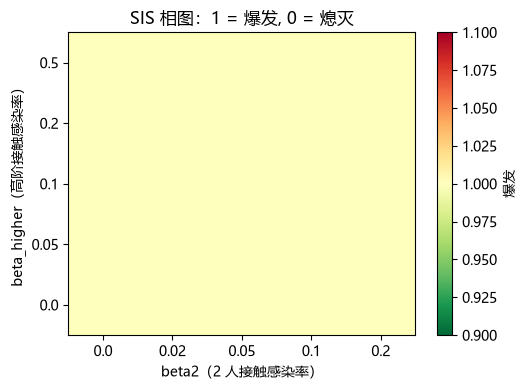

In [10]:
BETA2 = [0.0, 0.02, 0.05, 0.1, 0.2]
BETA_HIGHER = [0.0, 0.05, 0.1, 0.2, 0.5]

phase = honet.contagion.sis_phase(
    H,
    gamma=0.3,
    beta2_lst=BETA2,
    beta_higher_lst=BETA_HIGHER,
)
print("相图类型:", type(phase).__name__)
print("行 = beta_higher, 列 = beta2")
print(phase)
print(f"\n爆发比例: {phase.sum()} / {phase.size}")
print("\n注：这组参数下所有点都爆发，说明已整体越过阈值。")
print("   想看阈值边界需要更小的 beta 范围，但 6 结点小图很难出现熄灭区。")

plt.figure(figsize=(5.4, 4))
plt.imshow(phase, origin="lower", cmap="RdYlGn_r", aspect="auto")
plt.xticks(range(len(BETA2)), BETA2)
plt.yticks(range(len(BETA_HIGHER)), BETA_HIGHER)
plt.xlabel("beta2（2 人接触感染率）")
plt.ylabel("beta_higher（高阶接触感染率）")
plt.title("SIS 相图：1 = 爆发, 0 = 熄灭")
plt.colorbar(label="爆发")
plt.tight_layout()
plt.show()

## 9. 时变参数：感染力随时间变化

真实传播很少是参数恒定的：流感有季节性、防疫政策在特定日期调整、宣传活动
的效果随热度衰减。`tau` 与 `gamma` 除了常数，还可以传**接收时间返回取值**的
函数，模拟每步用当前时刻求值。

下面模拟「第 20 天起实施干预」：感染力骤降、恢复率上升。

In [11]:
import math

T_MAX = 80


def tau_seasonal(t):
    """感染力：前 20 天正常（带轻微周期起伏），之后降到 1/5。"""
    base = {2: 0.6, 3: 0.8}
    factor = 1.0 if t < 20 else 0.2
    # 周期性起伏，模拟「一周内的接触模式变化」
    ripple = 1.0 + 0.15 * math.sin(2 * math.pi * t / 7.0)
    return {size: rate * factor * ripple for size, rate in base.items()}


def gamma_policy(t):
    """恢复率：前 20 天 0.1，之后升到 0.4（更快康复）。"""
    return 0.1 if t < 20 else 0.4


t_tv, S_tv, I_tv = honet.contagion.random_discrete_sis(
    H, tau_seasonal, gamma_policy, rho=0.1, tmax=T_MAX, dt=1.0, seed=7
)
t_const, S_const, I_const = honet.contagion.random_discrete_sis(
    H, {2: 0.6, 3: 0.8}, 0.1, rho=0.1, tmax=T_MAX, dt=1.0, seed=7
)

print(f"常数参数 末态 I: {I_const[-1]}")
print(f"时变参数 末态 I: {I_tv[-1]}")
print(f"时变参数峰值 I: {max(I_tv)}  vs  常数参数峰值 I: {max(I_const)}")

常数参数 末态 I: 4
时变参数 末态 I: 0
时变参数峰值 I: 6  vs  常数参数峰值 I: 6


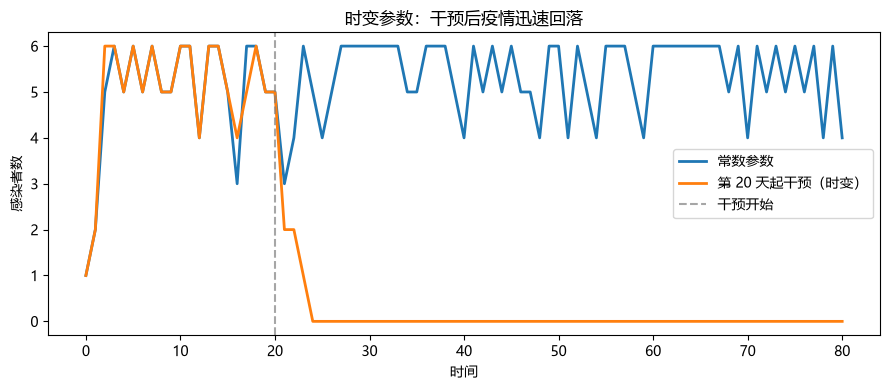

In [12]:
plt.figure(figsize=(9, 4))
plt.plot(t_const, I_const, label="常数参数", linewidth=2)
plt.plot(t_tv, I_tv, label="第 20 天起干预（时变）", linewidth=2)
plt.axvline(20, color="gray", linestyle="--", alpha=0.7, label="干预开始")
plt.xlabel("时间")
plt.ylabel("感染者数")
plt.title("时变参数：干预后疫情迅速回落")
plt.legend()
plt.tight_layout()
plt.show()

**为什么用函数而不是分段调用**：分段调用需要把模拟拆成多段手工拼接，
状态延续容易出错，也表达不了连续变化（如正弦式的季节性）。
传函数则由模型内部在每步求值，状态自然连续。

注意 `tau` 也可以直接传数值，等价于 `{2: 该值}`（只考虑成对交互）。

## 小结

| 需求 | 用哪个 |
| --- | --- |
| **画传播曲线** | `random_discrete_sis(H, tau, gamma, rho, tmax, dt)` |
| 时变感染力/恢复率 | `tau`、`gamma` 传 `Callable[[float], ...]` |
| 事件级分析 | `simulate(H, gamma, tau, model=...)` |
| 换模型 | `model="SIS"` / `"SIR"` / `"SEIR"` / `"SIER"` / `"SIRS"` / `"SI"` |
| 查内置模型 | `available_models()` / `get_model(name)` |
| 生成感染率表 | `generate_tau(H, beta=[...], type=...)` |
| 找阈值 | `sis_phase(...)` + `classify_point(...)` |
| 加控制 | `discrete_sis_control(...)` / `discrete_sir_control(...)` |

**四条关键提醒**：

1. **输入是 hypernetx 超图**，不是 `honet.Hypergraph`。
2. **`tau` 必须是字典** `{边大小: 感染率}`——高阶传染强度依赖参与人数。
3. **想画曲线用 `random_discrete_sis`**。`simulate` 返回事件流，点数很少。
4. **结果有随机性**。单个 seed 不能作为结论，必须多次平均（本 notebook 用 10 次）。